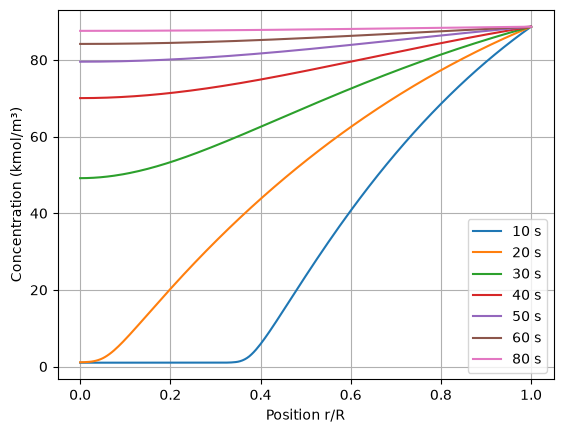

In [7]:
from firedrake import *
import numpy as np
import matplotlib.pyplot as plt

"""
For coupled diffusion problem, the firedrake implementation will be using mixing space between the displacement(u) and concentration(c). 
Here the solution is change to seeking radial displacement(w) and normalized concentration(q). The weak form of the coupled problem is defined in the code.
The mechanical properties are also included in the code.
"""

# same parameter values as before
R = 100e-9
D = 2.06e-18
c0 = 1.0                  
cmax = 88.67              
dt = 0.025                  

# mechanical properties necessary for coupled diffusion 
E = 80e9    # Young's modulus in Pa
nu = 0.22 # Poisson's ratio dimensionaless
Omega = 8.5e-6  # partial molar volume of Li in Si, m³/mol
#if omega = 0 then the mechanical effect is not considered in the diffusion problem i.e pure diffusion
R_g = 8.314     # constant
T = 298.15  # temperature kelvin

n_ele = 160
mesh = IntervalMesh(n_ele, 1.0)
x = SpatialCoordinate(mesh)[0] #r/R

V_w = FunctionSpace(mesh, "CG", 2) #displacement space tried quadratic and linear, linear is enough for this problem
#quadratic also works
V_q = FunctionSpace(mesh, "CG", 1)
W = V_w * V_q    # for coupled problem: w = displacement, q = concentration


state = Function(W) # holds both new unknowns
w, q = split(state)  # symbolic fields for writing the equations
test_w, test_q = TestFunctions(W)

q_p = Function(V_q) #function to hold the previous time step concentration
q_p.assign(0.0) #initialized to 0

#W.sub(0) is the displacement space, W.sub(1) is the concentration space

bc = DirichletBC(W.sub(1), 1.0, 2)  # q = 1 at the surface
bc.apply(state)
DirichletBC(V_q, 1.0, 2).apply(q_p) # apply the boundary condition to the previous time step concentration

c = c0 + (cmax - c0) * q  # actual concentration

# define stress strain and the weak form of the coupled problem
"the displacement creates total strain;"
"lithium concentration creates swelling strain; and Hooke law converts the difference into stress."


swelling = Omega*(c - c0)/3  *1000 # swelling strain due to lithium concentration, 1000 is the unit conversion from m to mm

#displacement -> strain
strain_rr = w + x* grad(w)[0]  
#with u_r = r*w the physical displacement, the radial strain is defined as strain_rr = du_r/dr = w + r*dw/dr = w + x*dw/dx
strain_tt = w
elastic_trace = strain_rr + strain_tt - 3 * swelling

# stress divided by E, to keep the numerical equations well scaled(dimensionless), equations are isotropic hookes law refering to section on the research paper.
#I used the scaled stresses because the mechanical equilibrium equation is zero, so a common factor of E cancels.
SoE_rr = ( 
    (strain_rr - swelling) / (1 + nu)
    + nu * elastic_trace / ((1 + nu) * (1 - 2*nu))
)
SoE_tt = (
    (strain_tt - swelling) / (1 + nu)
    + nu * elastic_trace / ((1 + nu) * (1 - 2*nu))
)

SoE_h = elastic_trace / (3 * (1 - 2*nu)) # hydrostatic stress


#stress -> mechanical weak form in radial coordinate. 
#given the current concentration-induced swelling, what radial displacement makes the internal forces balance?
F_mech = x * (
    SoE_rr * (test_w + x * grad(test_w)[0])
    + SoE_tt * test_w
) * dx


sf = Omega * E / (R_g * T) #stress factor is used to restore the unit of stress to the unit of concentration, 
#so that the two terms in the diffusion weak form are comparable.
dc = cmax - c0  # the change of concentration from the initial to the maximum, used to normalize the stress effect in the diffusion weak form
Theta = 2 * Omega**2 * E / (9 * R_g * T * (1 - nu))

#F_diff is the residual of the diffusion equation, which is the weak form of the diffusion equation.
#first term is ordinary diffusionm second part is the change of flux when hydrostatic stress is considered.
F_diff = x * (
    (q - q_p) * test_q / dt
    + (D / R**2) * (
        (1 + Theta * 1000 * c) * grad(q)[0]
    ) * grad(test_q)[0] #c = c0 + dc *q, r = Rx
) * dx

#using conservation of lithium and backward Euler in time gives the radial weak form, that is F_diff = 0.

#nonlinear variational problem and solver, assembles both sets of equations into one solve. 
# It cannot let errors cancel between them. The test functions are therefore independent.
F= F_mech + F_diff
problem = NonlinearVariationalProblem(F, state, bcs=[bc])
solver = NonlinearVariationalSolver(problem)



""" one Newton solve finds the new displacement and concentration together,
 satisfying both equations. Mechanics is treated as quasi-static at each time step; 
 the initial-value time evolution belongs to the concentration equation.
 
 note on solver's choice:
 
 "snes_type": "newtonls"	Use Newton’s method to handle the nonlinear coupling. ls means a line-search form of Newton.
"mat_type": "aij"	Store the assembled equations as a conventional sparse matrix.
"ksp_type": "preonly"	Do not run an iterative linear solver inside each Newton step; apply the chosen direct solve.
"pc_type": "lu"	Solve that linear system by LU factorisation.
 
 """
node = np.linspace(0, 1, 201)
sampler = PointEvaluator(mesh, node[:, None]) #makes it easy to sample the solution at a set of points in the domain,
#for plotting and analysis.
profiles = {} #again dictionary is used to hold the concentration profiles at different times
stress_profiles = {}

sample_times = [10.0, 20.0, 30.0, 40.0, 50, 60, 80] #time points to sample the concentration profiles
sample_steps = {round(time / dt): time for time in sample_times}

rates = {}
rate_times = []
max_rates = []

soc_times = [0.0]
soc = [c0 / cmax]

for t in range(1, max(sample_steps) + 1):
    solver.solve()

    current_values = sampler.evaluate(state.subfunctions[1])
    previous_values = sampler.evaluate(q_p)
    rate = dc * (current_values - previous_values) / dt

    rate_times.append(t * dt)
    max_rates.append(np.max(rate))

    soc_times.append(t * dt)
    soc.append(assemble((c / cmax) * dx))

    if t in sample_steps:  # store the concentration profiles at these time steps
        time = sample_steps[t]
        profiles[time] = c0 + dc * current_values
        rates[time] = rate.copy()

        #project turns the stress expression into a finite-element function that sampler can evaluate
        stress_field = project(E * SoE_h / 1e9, V_q)
        stress_hy = sampler.evaluate(stress_field)
        stress_profiles[time] = stress_hy.copy()

    q_p.assign(state.subfunctions[1])



for time, concentration in profiles.items():
    plt.plot(node, concentration, label=f"{time:g} s")

plt.xlabel("Position r/R")
plt.ylabel("Concentration (kmol/m³)")
plt.legend()
plt.grid(True)
plt.show()

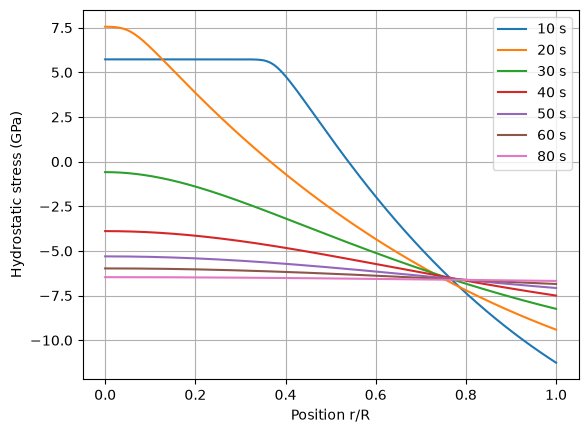

In [8]:
#plot against hydrostatic stress
plt.figure()

for time in sorted(stress_profiles):
    plt.plot(node, stress_profiles[time], label=f"{time:g} s")

plt.xlabel("Position r/R")
plt.ylabel("Hydrostatic stress (GPa)")
plt.legend()
plt.grid(True)
plt.show()

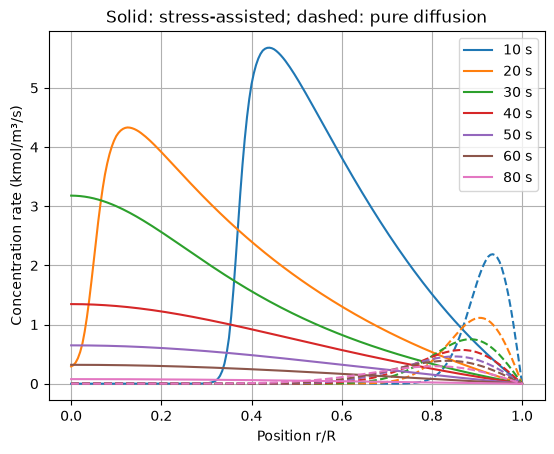

In [9]:
# pure diffusion: separate concentration functions
q_pure = Function(V_q)
q_pure_old = Function(V_q)
q_pure_old.assign(0.0)

bc_pure = DirichletBC(V_q, 1.0, 2)
bc_pure.apply(q_pure_old)

trial_pure = TrialFunction(V_q)
test_pure = TestFunction(V_q)

lhs_pure = x * (
    trial_pure * test_pure / dt
    + (D / R**2) * dot(grad(trial_pure), grad(test_pure))
) * dx

rhs_pure = x * q_pure_old * test_pure / dt * dx

problem_pure = LinearVariationalProblem(
    lhs_pure, rhs_pure, q_pure, bcs=[bc_pure]
)
solver_pure = LinearVariationalSolver(problem_pure)

sample_times = [10.0, 20.0, 30.0, 40.0, 50, 60, 80] #time points to sample the concentration profiles
sample_steps = {round(time / dt): time for time in sample_times} #round is just for completeness


pure_profiles = {}

pure_rates = {}
pure_rate_times = []


pure_soc_times = [0.0]
pure_soc = [c0 / cmax]


for step in range(1, max(sample_steps) + 1):
    solver_pure.solve()

    current_values = sampler.evaluate(q_pure)
    previous_values = sampler.evaluate(q_pure_old)
    rate = dc * (current_values - previous_values) / dt #easy to calculate the rate of change 

    pure_rate_times.append(step * dt)

    pure_soc_times.append(step * dt)
    pure_soc.append(assemble(((c0 + dc * q_pure) / cmax) * dx))

    if step in sample_steps:
        time = sample_steps[step]
        pure_profiles[time] = c0 + dc * current_values
        pure_rates[time] = rate.copy()

    q_pure_old.assign(q_pure)

    
# Local concentration rate at selected times
plt.figure()

for time in sorted(rates):
    line, = plt.plot(node, rates[time], label=f"{time:g} s")
    plt.plot(
        node, pure_rates[time],
        "--", color=line.get_color()
    )

plt.xlabel("Position r/R")
plt.ylabel("Concentration rate (kmol/m³/s)")
plt.title("Solid: stress-assisted; dashed: pure diffusion")
plt.legend()
plt.grid(True)
plt.show()

#plot of the maximum local concentration rate in time does not provide much insight here. I've tried.



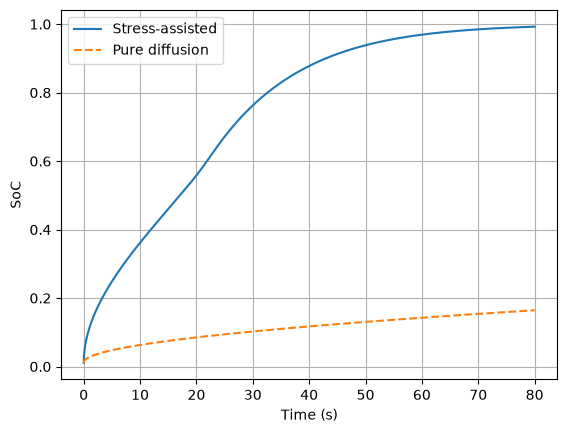

In [10]:
plt.figure()

plt.plot(soc_times, soc, label="Stress-assisted")
plt.plot(pure_soc_times, pure_soc, "--", label="Pure diffusion")

plt.xlabel("Time (s)")
plt.ylabel("SoC")
plt.legend()
plt.grid(True)
plt.show()